# 05 · Can we trust the model's confidence?

**RQ4.** Explanations tell a user *why* a venue was suggested; confidence tells them
*whether to believe it*. The original project plotted the entropy of the predictions and
listed confident mistakes. Here we test the claim properly:

1. Does low entropy actually separate right from wrong recommendations?
2. Is the model **calibrated** — when it says 80%, is it right 80% of the time?
   (reliability diagram, ECE; Guo et al., 2017)
3. Does **temperature scaling** (fitted without touching the test set) fix it, and how
   much of the miscalibration is caused by the **train/test label shift** (Saerens et
   al., 2002)?
4. If the recommender may **abstain** on uncertain titles, how much more reliable are
   the answers it does give? (selective prediction; Geifman & El-Yaniv, 2017)

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold

from tcner_xai import calibration as C
from tcner_xai import plotting
from tcner_xai.config import CLASSES, RESULTS_DIR, SEED
from tcner_xai.explain import RemovalGame, exact_shapley, word_types
from tcner_xai.model import VenueClassifier, load_bundle

plotting.set_style()
pd.set_option("display.max_colwidth", 90)
B = load_bundle()
model, train, test = B.model, B.train, B.test
logits = model.clf.decision_function(B.X_test)
proba = C.ovr_proba(logits)
assert np.allclose(proba, model.clf.predict_proba(B.X_test))
y_idx = np.array([model.class_index(c) for c in B.y_test])
pred = proba.argmax(1)
correct = pred == y_idx

train=21,497 test=3,373 features=5,000 test accuracy=0.8615


## 1. Entropy separates right from wrong — but only partly

Entropy is normalised by log(5) so it lies in [0, 1].

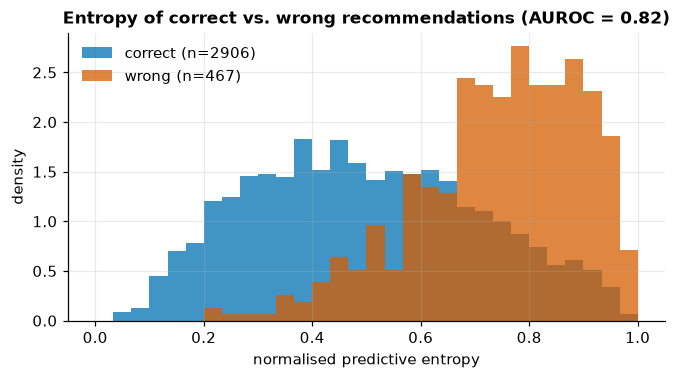

AUROC of entropy for flagging errors: 0.819
wrong predictions with entropy below the median of correct ones: 7.3%


In [2]:
H = C.entropy(proba)
auroc = roc_auc_score(~correct, H)
fig, ax = plt.subplots(figsize=(7, 3.4))
bins = np.linspace(0, 1, 31)
ax.hist(H[correct], bins=bins, alpha=0.75, label=f"correct (n={correct.sum()})", color="#0072B2", density=True)
ax.hist(H[~correct], bins=bins, alpha=0.75, label=f"wrong (n={(~correct).sum()})", color="#D55E00", density=True)
ax.set_xlabel("normalised predictive entropy")
ax.set_ylabel("density")
ax.set_title(f"Entropy of correct vs. wrong recommendations (AUROC = {auroc:.2f})")
ax.legend()
plotting.save(fig, "05_entropy_correct_vs_wrong")
plt.show()
print(f"AUROC of entropy for flagging errors: {auroc:.3f}")
print(f"wrong predictions with entropy below the median of correct ones: "
      f"{(H[~correct] < np.median(H[correct])).mean():.1%}")

## 2–3. Calibration, temperature scaling and label shift

The temperature is fitted on **out-of-fold** predictions for the *training* titles
(5-fold cross-validation, vectoriser refitted inside each fold), so the test set is used
only for evaluation. The prior-shift correction (EM, Saerens et al., 2002) uses the test
*titles* but never their labels.

In [3]:
oof = np.zeros((len(train), len(CLASSES)))
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
for tr, va in skf.split(train["clean"], train["label"]):
    m = VenueClassifier().fit(train["clean"].iloc[tr], train["label"].iloc[tr])
    oof[va] = m.logit_clean(train["clean"].iloc[va])
y_train_idx = np.array([model.class_index(c) for c in train["label"]])
T = C.fit_temperature(oof, y_train_idx)
print(f"fitted temperature T = {T:.3f}  (T > 1 softens, T < 1 sharpens the probabilities)")

train_prior = np.bincount(y_train_idx, minlength=5) / len(y_train_idx)
proba_T = C.ovr_proba(logits, T)
proba_em, est_prior = C.em_prior_adjustment(proba, train_prior)
proba_T_em, est_prior_T = C.em_prior_adjustment(proba_T, train_prior)
true_prior = np.bincount(y_idx, minlength=5) / len(y_idx)
display(pd.DataFrame({"train prior": train_prior, "true test prior": true_prior,
                      "EM-estimated test prior": est_prior_T}, index=model.classes_).round(3))

variants = {"original": proba, "temperature scaled": proba_T, "prior-shift corrected (EM)": proba_em,
            "temperature + prior shift": proba_T_em}
cal_rows = []
for name, P in variants.items():
    p = P.argmax(1)
    cal_rows.append({"variant": name, "accuracy": (p == y_idx).mean(),
                     "macro F1": f1_score(y_idx, p, average="macro"),
                     "ECE": C.ece(P, y_idx), "NLL": C.nll(P, y_idx), "Brier": C.brier(P, y_idx),
                     "mean confidence": P.max(1).mean()})
cal = pd.DataFrame(cal_rows).set_index("variant").round(4)
cal.to_csv(RESULTS_DIR / "calibration_summary.csv")
display(cal)

fitted temperature T = 0.600  (T > 1 softens, T < 1 sharpens the probabilities)


,train prior,true test prior,EM-estimated test prior
INFOCOM,0.206,0.149,0.130
ISCAS,0.350,0.606,0.652
SIGGRAPH,0.122,0.055,0.039
VLDB,0.169,0.065,0.068
WWW,0.153,0.125,0.112


,accuracy,macro F1,ECE,NLL,Brier,mean confidence
variant,,,,,,
original,0.8615,0.7778,0.1533,0.5141,0.2401,0.7083
temperature scaled,0.8615,0.7778,0.0198,0.4126,0.2036,0.8578
prior-shift corrected (EM),0.8233,0.6811,0.0329,0.4834,0.2459,0.7927
temperature + prior shift,0.8562,0.7636,0.0318,0.4164,0.2101,0.8816


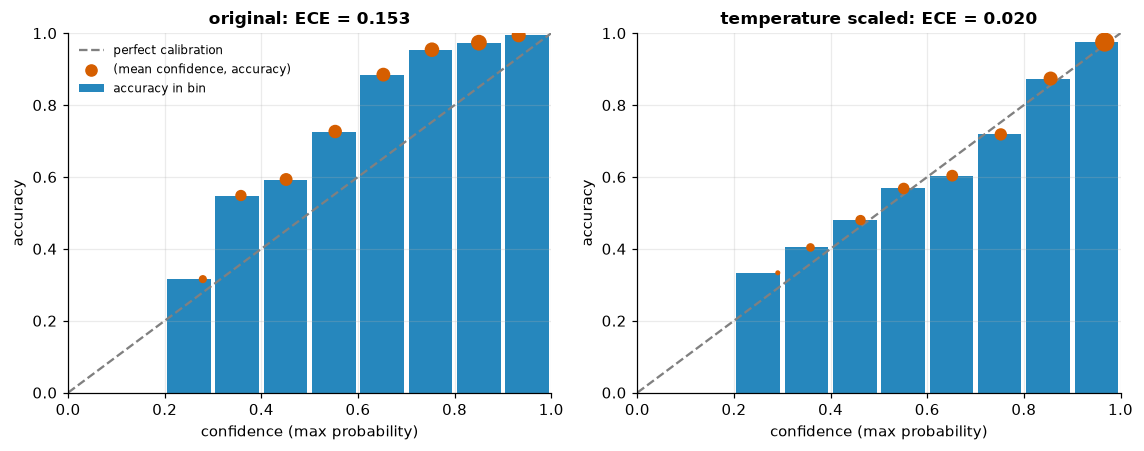

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
for ax, (name, P) in zip(axes, [("original", proba), ("temperature scaled", proba_T)]):
    e, table = C.reliability(P, y_idx, n_bins=10)
    centers = (table[:, 0] + table[:, 1]) / 2
    ax.bar(centers, table[:, 4], width=0.09, color="#0072B2", alpha=0.85, label="accuracy in bin")
    ax.plot([0, 1], [0, 1], "--", color="gray", label="perfect calibration")
    ax.scatter(table[:, 3], table[:, 4], s=np.sqrt(table[:, 2]) * 3, color="#D55E00", zorder=3,
               label="(mean confidence, accuracy)")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xlabel("confidence (max probability)")
    ax.set_ylabel("accuracy")
    ax.set_title(f"{name}: ECE = {C.ece(P, y_idx):.3f}")
axes[0].legend(fontsize=8, loc="upper left")
fig.tight_layout()
plotting.save(fig, "05_reliability_diagrams")
plt.show()

## 4. Selective prediction: let the recommender say “not sure”

Sort titles by confidence and only answer the most confident fraction. The
risk–coverage curve shows accuracy on the answered titles; the area under the risk
curve (AURC) summarises it (lower is better). In a venue-recommendation tool, the
abstained titles could instead get a *ranked shortlist* — the top-2 accuracy row shows
what that buys.

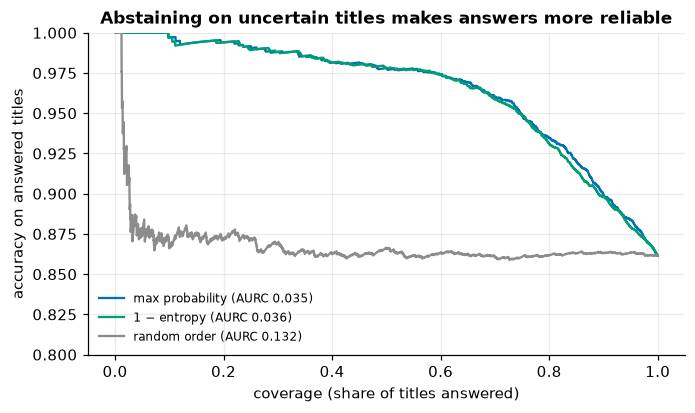

,AURC,accuracy @ 80% coverage,accuracy @ 50% coverage,max coverage with ≥95% accuracy,max coverage with ≥98% accuracy
ranking,,,,,
max probability,0.0353,0.934800,0.9781,0.7477,0.4761
1 − entropy,0.0362,0.931100,0.9781,0.7433,0.4622
random order,0.1322,0.861700,0.8660,0.0139,0.0119
"(reference) top-2 shortlist, all titles",NaN,0.955826,NaN,NaN,NaN


In [5]:
fig, ax = plt.subplots(figsize=(7, 3.8))
sel_rows = []
for name, conf, color in [("max probability", proba_T.max(1), "#0072B2"),
                          ("1 − entropy", 1 - C.entropy(proba_T), "#009E73"),
                          ("random order", np.random.default_rng(SEED).random(len(y_idx)), "#8C8C8C")]:
    cov, acc, aurc = C.risk_coverage(conf, proba_T.argmax(1) == y_idx)
    ax.plot(cov, acc, label=f"{name} (AURC {aurc:.3f})", color=color)
    sel_rows.append({"ranking": name, "AURC": aurc,
                     "accuracy @ 80% coverage": acc[int(0.8 * len(acc)) - 1],
                     "accuracy @ 50% coverage": acc[int(0.5 * len(acc)) - 1],
                     "max coverage with ≥95% accuracy": C.coverage_at_accuracy(cov, acc, 0.95),
                     "max coverage with ≥98% accuracy": C.coverage_at_accuracy(cov, acc, 0.98)})
ax.set_xlabel("coverage (share of titles answered)")
ax.set_ylabel("accuracy on answered titles")
ax.set_ylim(0.8, 1.0)
ax.set_title("Abstaining on uncertain titles makes answers more reliable")
ax.legend(fontsize=8)
plotting.save(fig, "05_risk_coverage")
plt.show()
sel = pd.DataFrame(sel_rows).set_index("ranking").round(4)
ranked = np.argsort(-proba_T, axis=1)
sel.loc["(reference) top-2 shortlist, all titles", "accuracy @ 80% coverage"] = np.mean(
    [y in r[:2] for y, r in zip(y_idx, ranked)])
sel.to_csv(RESULTS_DIR / "selective_prediction.csv")
display(sel)

## 5. Why is the model confidently wrong? Explaining the overconfident errors

The five lowest-entropy mistakes, each with the exact Shapley top words for the
predicted venue. This links the confidence analysis to the local explanations.

In [6]:
wrong = np.flatnonzero(~correct)
worst = wrong[np.argsort(H[wrong])][:8]
rows = []
for i in worst:
    clean = test.loc[i, "clean"]
    g = RemovalGame(model, clean)
    if g.n == 0 or g.n > 14:
        continue
    phi = exact_shapley(g)["proba"][:, pred[i]]
    top = np.argsort(-phi)[:3]
    rows.append({"title": test.loc[i, "title"], "true": B.y_test[i], "predicted": model.classes_[pred[i]],
                 "P(pred)": round(proba[i, pred[i]], 3), "norm. entropy": round(H[i], 3),
                 "driving words (exact Shapley)": ", ".join(f"{g.players[j]} {phi[j]:+.2f}" for j in top)})
over = pd.DataFrame(rows).head(6)
over.to_csv(RESULTS_DIR / "overconfident_errors.csv", index=False)
display(over)

,title,true,predicted,P(pred),norm. entropy,driving words (exact Shapley)
0,Matching Titles with Cross Title Web-Search Enrichment and Community Detection.,VLDB,WWW,0.923,0.217,"web +0.42, search +0.24, community +0.21"
1,Processing scientific mesh queries in graph databases.,WWW,VLDB,0.922,0.222,"database +0.43, query +0.28, process +0.06"
2,Deduplicating a places database.,WWW,VLDB,0.920,0.235,"database +0.78, deduplicate +0.00, place -0.03"
3,Biperpedia: An Ontology for Search Applications.,VLDB,WWW,0.895,0.278,"ontology +0.40, search +0.36, biperpedia +0.00"
4,SPOT: Locating Social Media Users Based on Social Network Context.,VLDB,WWW,0.872,0.325,"social +0.46, user +0.15, medium +0.14"
5,Silencing the noise on <i>Elysium</i>.,SIGGRAPH,ISCAS,0.870,0.335,"noise +0.58, silence +0.00, elysium</i +0.00"


## Take-aways

* **The model is under-confident, not over-confident.** Its mean confidence (≈ 0.71) is
  well below its accuracy (≈ 0.86); the reliability diagram lies *above* the diagonal.
  The original report concluded “overconfidence” from a handful of confident mistakes —
  anecdotal evidence that the aggregate calibration analysis contradicts. Confident
  mistakes do exist but are rare.
* A single **temperature (T ≈ 0.6) fitted on training folds** removes almost all of the
  miscalibration on the untouched test set and leaves the ranking (and accuracy) unchanged.
* The **label-shift correction** (EM) estimates the new venue mix well but *lowers*
  accuracy: EM assumes calibrated posteriors, which this model does not have. Even after
  temperature scaling it does not beat temperature scaling alone, so we do not recommend it.
* Entropy separates right from wrong reasonably (AUROC ≈ 0.82). The overconfident errors
  are *understandable*: their driving words (e.g. `database`, `web`, `social`) genuinely
  belong to the predicted venue's vocabulary.
* **Selective prediction** turns confidence into a product feature: the recommender can
  answer about 70% of titles at ≥ 95% accuracy and offer the rest a top-2 shortlist
  (which contains the right venue for ≈ 96% of all titles).